
Elapsed time: 2s | Remaining time: 1s

Elapsed time: 3s | Remaining time: 1s

Elapsed time: 3s | Remaining time: 0s


0.9493
-Image-   -Image-   -Image-   -Image-   -Image-

6         4         9         8         3
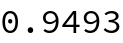
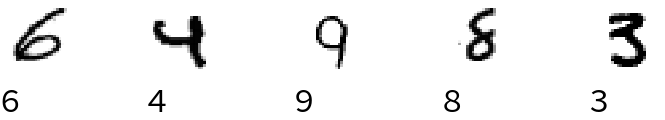

In [6]:
resource = ResourceObject["MNIST"];
trainingData = ResourceData[resource, "TrainingData"];
testData = ResourceData[resource, "TestData"];

net = NetChain[{FlattenLayer[], LinearLayer[900], 
    ElementwiseLayer[Ramp], LinearLayer[10], SoftmaxLayer[]}, 
   "Input" -> NetEncoder[{"Image", 30, ColorSpace -> "Grayscale"}], 
   "Output" -> NetDecoder[{"Class", Range[0, 9]}]];
net = NetTrain[net, trainingData, ValidationSet -> testData, 
 MaxTrainingRounds -> 3];

 NetMeasurements[net, testData, "Accuracy"]
 imgs = Keys @ RandomSample[testData, 5];
 TableForm[{imgs,net[imgs]}]

-Graphics-
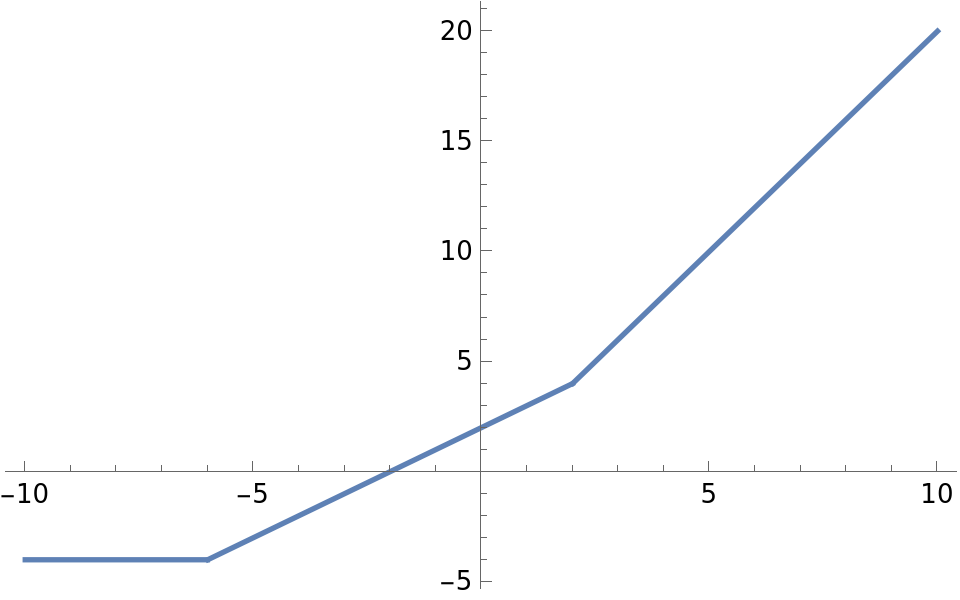

In [12]:
SetAttributes[Tropical,HoldAllComplete];
Tropical[expr_] := 
  ReleaseHold[
   HoldComplete[expr] /. {Plus -> CirclePlus, Times -> CircleTimes, 
     Power[a_, b_] /; b > 0 :> CircleTimes @@ ConstantArray[a, b]}];
TropicalEvaluate[expr_] := 
  expr /. {CirclePlus -> Max, CircleTimes -> Plus, 
    Power[a_, -1] :> -TropicalEvaluate[a]};

Plot[TropicalEvaluate[Tropical[x^2+2x-4]] // Evaluate, {x, -10, 10}]

-Graphics-
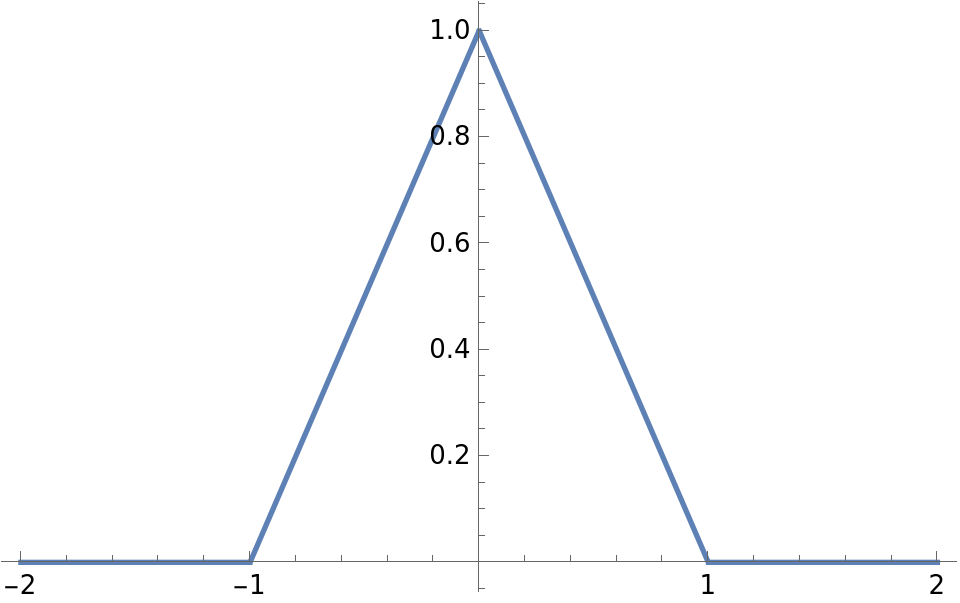

In [13]:
Plot[Tropical[(x^2 + 1 x + 0)/(x^2 + 0)] // TropicalEvaluate // Evaluate, {x, -2, 2}]

-Graphics-
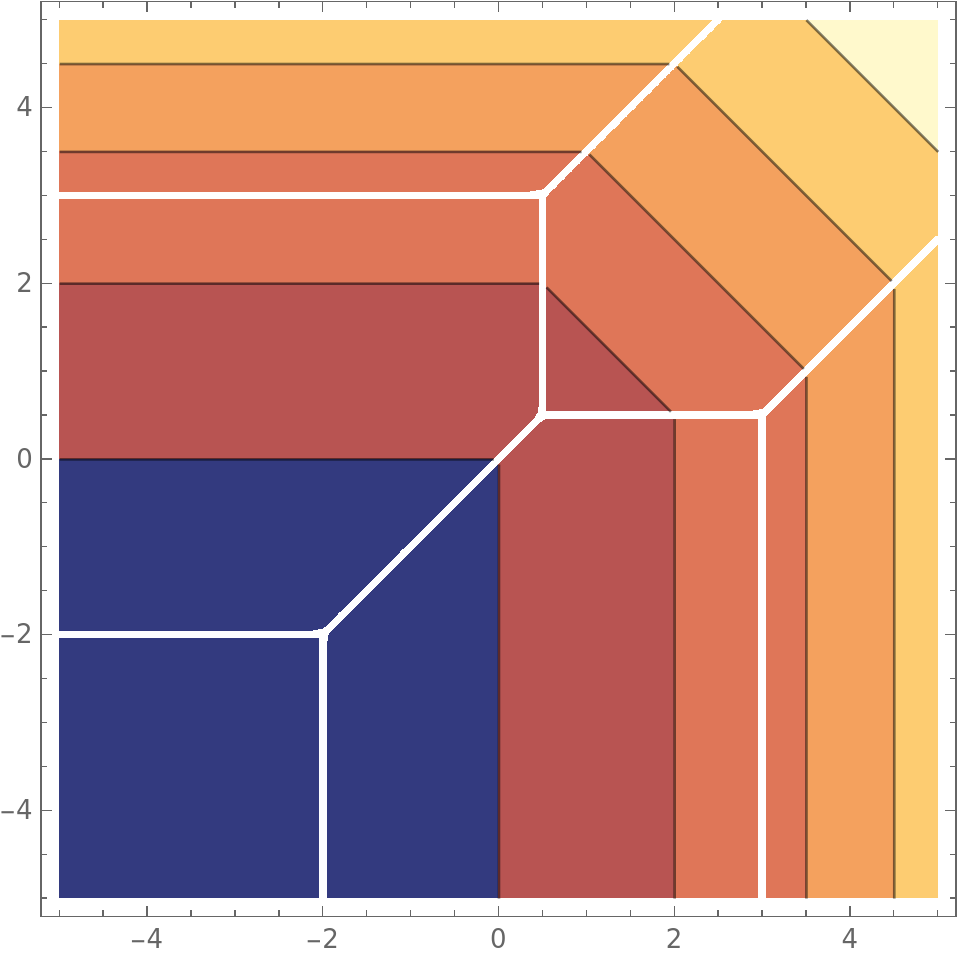

In [15]:
poly = Tropical[-1 x1^2 + 1.5 x1 x2 - x2^2 + 2 x1 + 2 x2 + 0];
ContourPlot[Evaluate[TropicalEvaluate[poly]], {x1, -5, 5}, {x2, -5, 5}]

-Graphics-
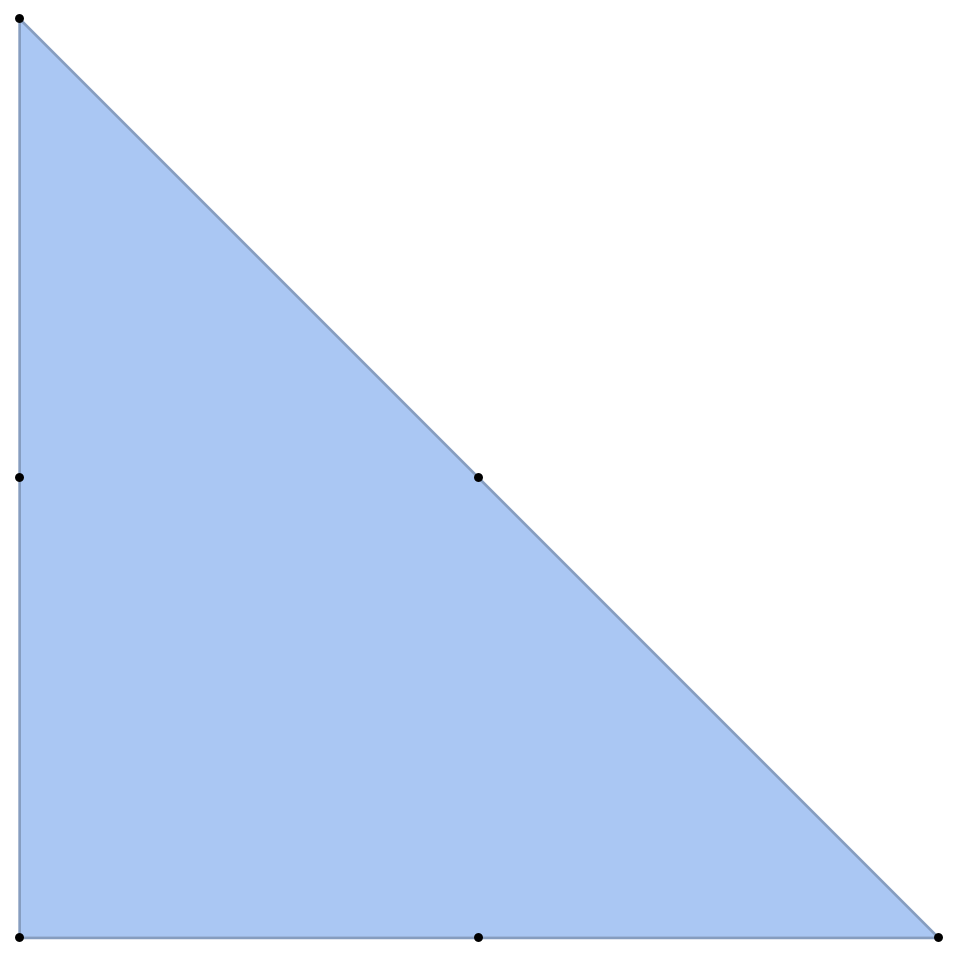

In [18]:
MonomialData[expr_, vars_] := 
 Table[With[{normal = term /. CircleTimes -> Times}, {normal /. 
     Table[v -> 1, {v, vars}], 
    Table[If[normal === 0, 0, x D[normal, x]/normal], {x, 
      vars}]}], {term, List @@ expr}]
NewtonPolygon[expr_, vars_] := 
  With[{pts = Last /@ MonomialData[expr, vars]}, {ConvexHullMesh[pts],
     Graphics[Point[pts]]}];

Show[NewtonPolygon[poly, {x1, x2}]]

BoundaryMeshRegion[<3>, <3>]
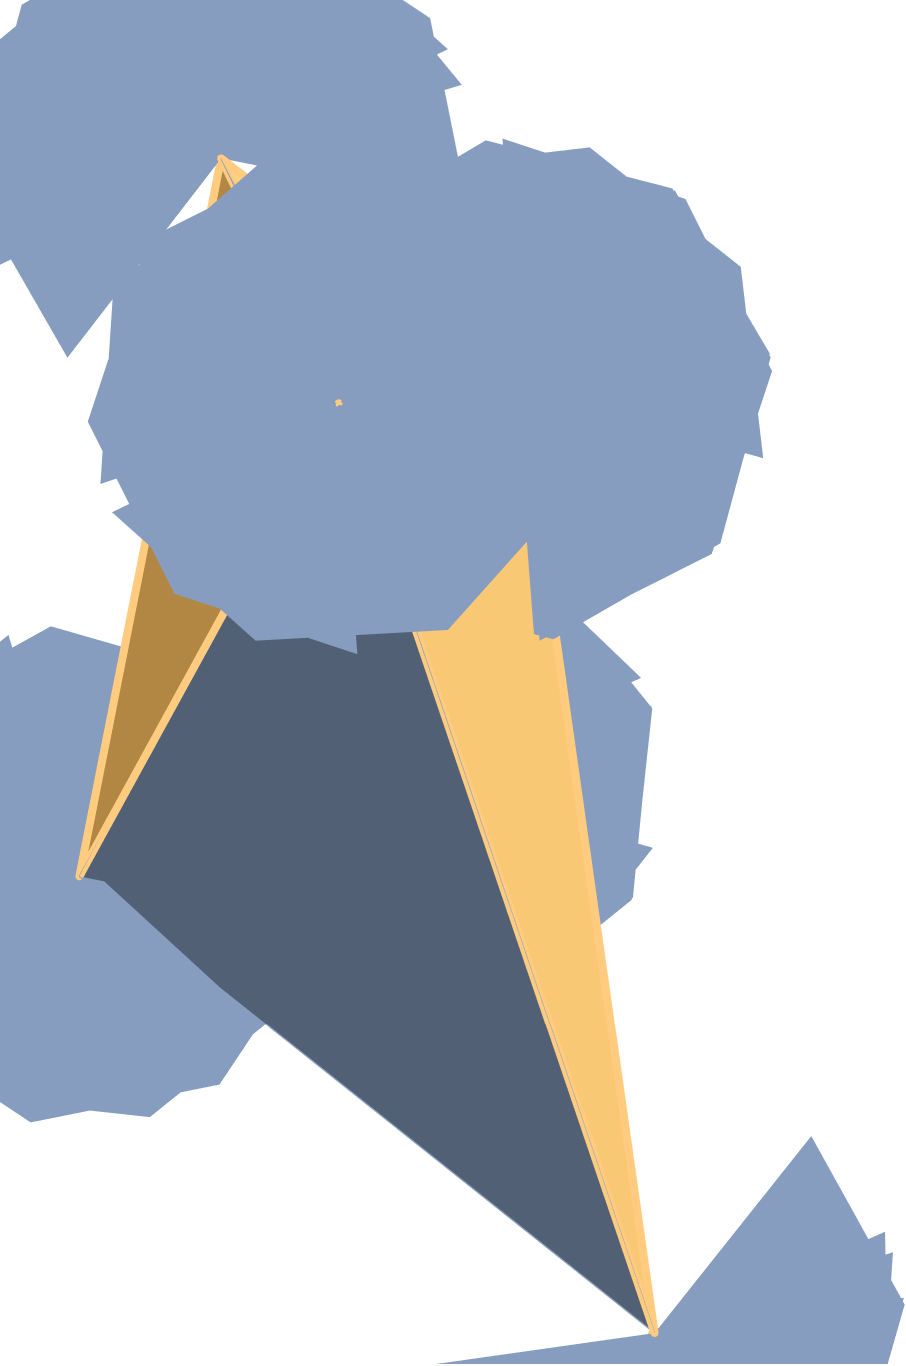

In [23]:
LiftedNewtonPolygon[expr_, vars_] := 
  With[{mons = MonomialData[expr, vars]}, 
   Table[Join[Last[mon], {First[mon]}], {mon, mons}]];
NormalVector[face_, coordinates_] := 
  Normalize[
   Total[Table[
     Cross[coordinates[[xs[[2]]]] - coordinates[[xs[[1]]]], 
      coordinates[[xs[[3]]]] - coordinates[[xs[[2]]]]], {xs, 
      Table[RotateLeft[First[face], rot], {rot, 
        Length[First[face]]}]}]]];
UpperFaces[mesh_] := 
  With[{pts = MeshCoordinates[mesh], faces = MeshCells[mesh, 2]}, 
   MeshRegion[pts, Select[faces, Last[NormalVector[#, pts]] > 0 &]]];

P = ConvexHullMesh[LiftedNewtonPolygon[poly, {x1, x2}]];
HighlightMesh[P, UpperFaces[P]]

-Graphics-
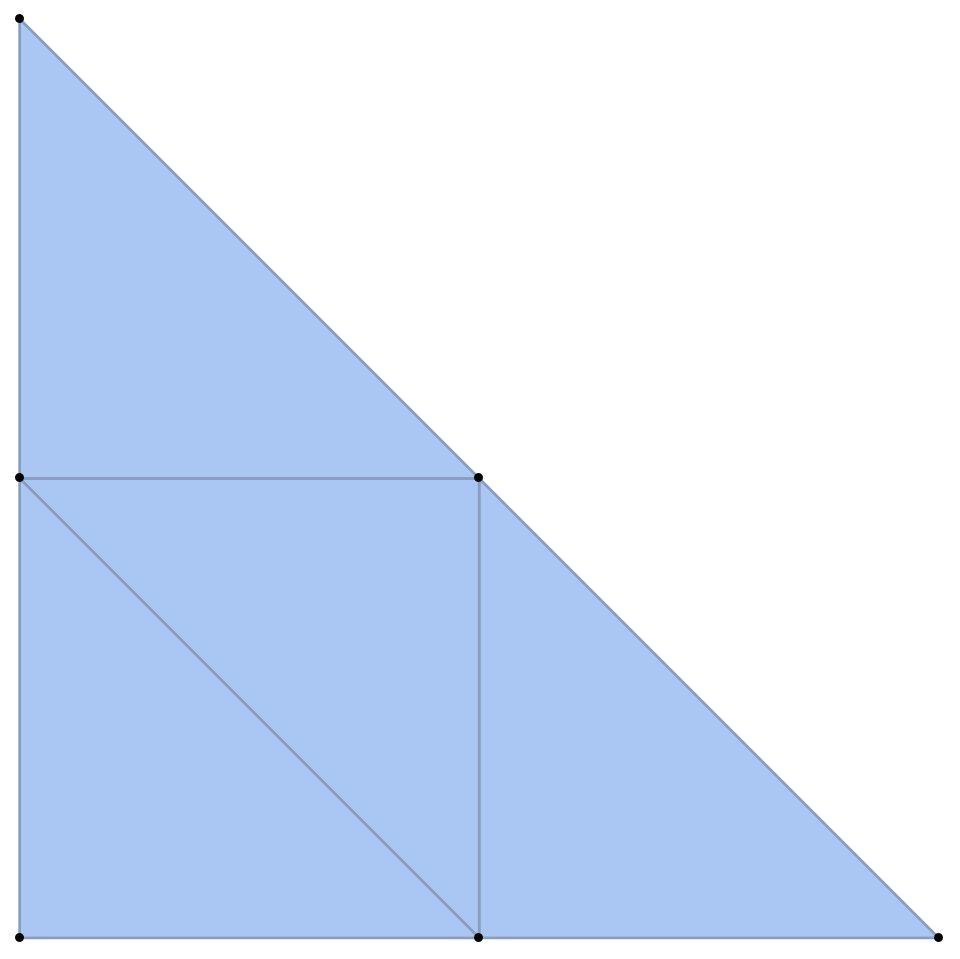

In [26]:
ProjectFaces[mesh_] := 
  With[{pts = MeshCoordinates[mesh], faces = MeshCells[mesh, 2]},
   MeshRegion[Most /@ pts, faces]];

NewtonSubdivision[expr_, vars_] := 
  With[{pts = LiftedNewtonPolygon[expr, vars]},
   {ProjectFaces@UpperFaces@ConvexHullMesh@pts, 
    Graphics[Point[Most /@ pts]]}];

Show[NewtonSubdivision[poly, {x1, x2}]]

-Graphics-
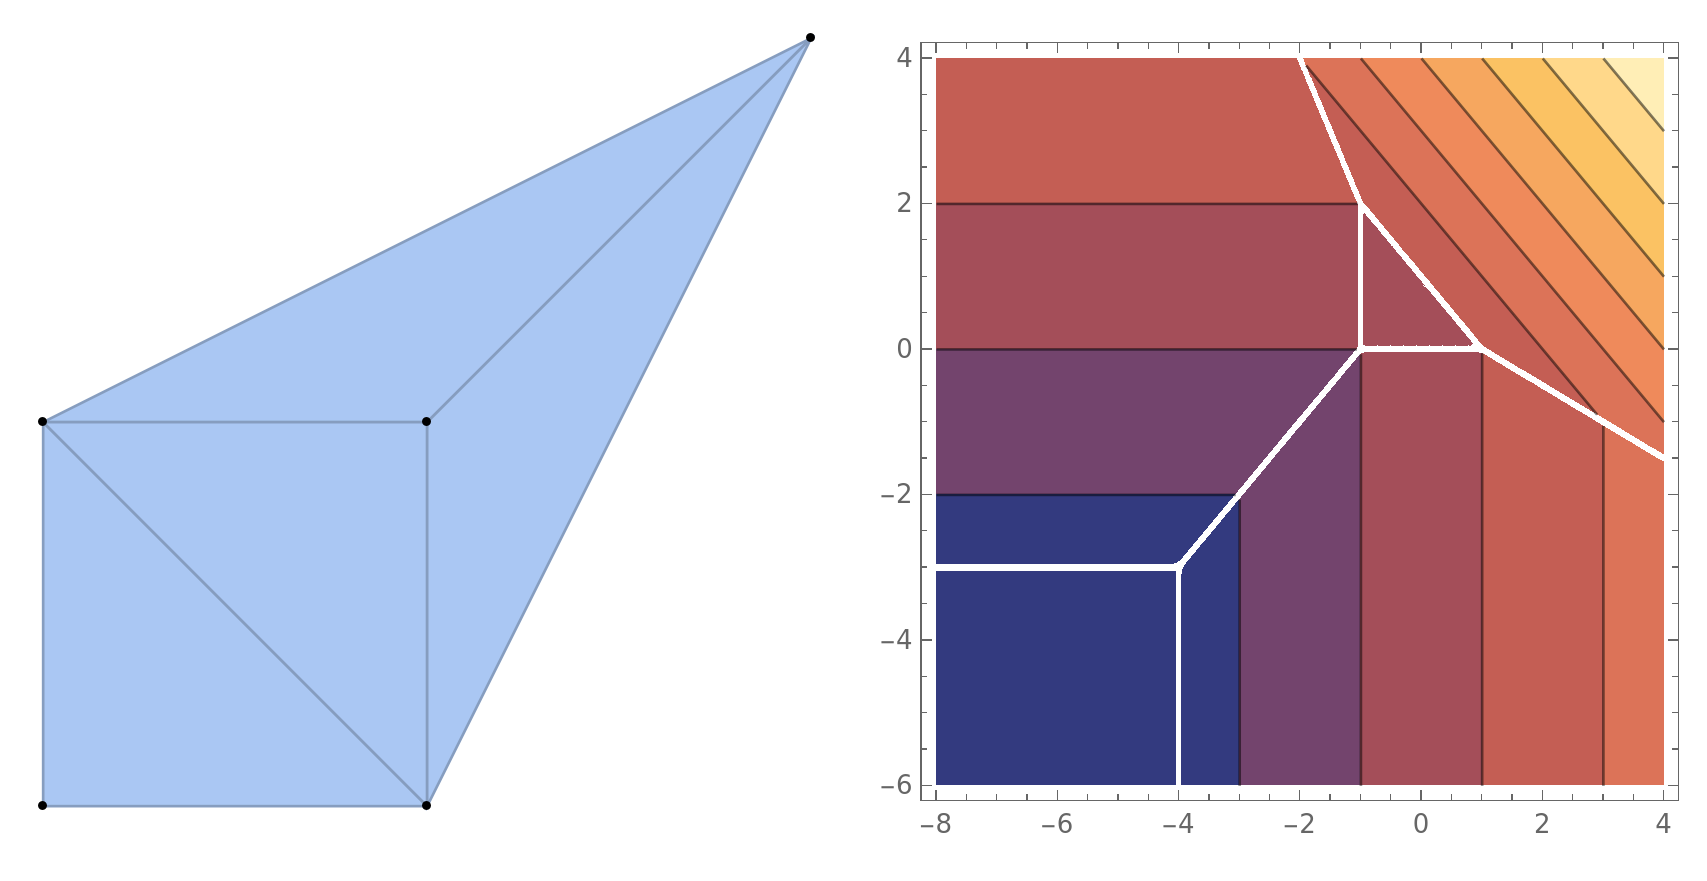

In [28]:
poly2 = Tropical[1 x1 x2 + 1 x1 - 1 x2 - 1 x1^2 x2^2 - 3];
GraphicsRow[{Show[NewtonSubdivision[poly2, {x1, x2}]], ContourPlot[TropicalEvaluate[poly2] // Evaluate, {x1, -8, 4}, {x2, -6, 4}]}]

-Graphics-
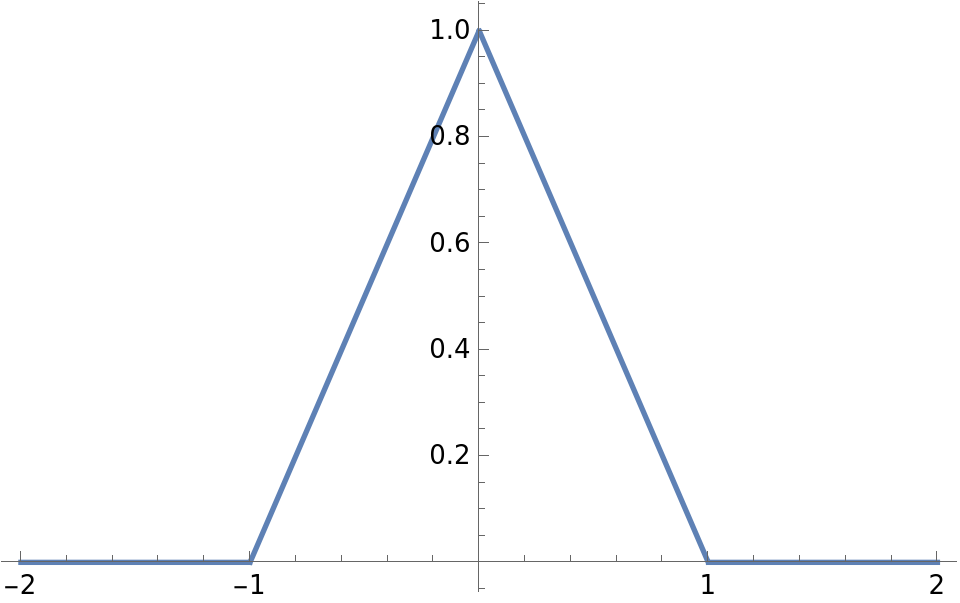

In [29]:
Plot[Ramp[Ramp[x+1] - 2 Ramp[x]], {x, -2, 2}]

3            4            5            6

-Graphics-   -Graphics-   -Graphics-   -Graphics-
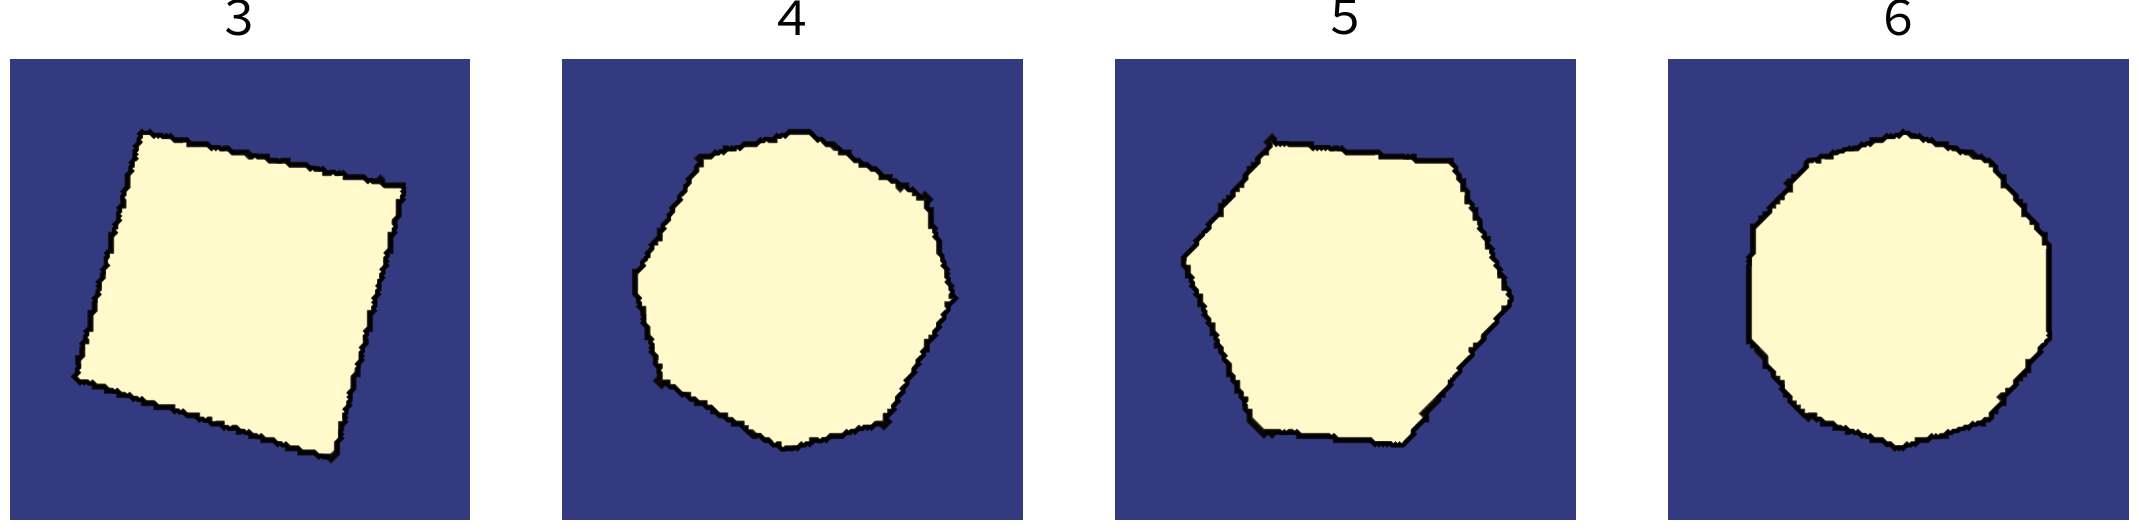

In [32]:
circleTraining = 
  Flatten[Table[{x, y} -> (Norm[{x, y}] < 1), {x, 
     Subdivide[-1.5, 1.5, 100]}, {y, Subdivide[-1.5, 1.5, 100]}]];

plotNet[net_] := 
 ContourPlot[If[net[{x, y}], 1, 0], {x, -1.5, 1.5}, {y, -1.5, 1.5}, 
  Frame -> False]

TableForm[Transpose[Table[
   net = NetChain[{LinearLayer[width], ElementwiseLayer[Ramp], 
      LinearLayer[], LogisticSigmoid}];
   net = NetTrain[net, circleTraining];
   {Style[width, 20], plotNet[net]}, {width, Range[3, 6]}]], 
 TableAlignments -> Center]